<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/course-notebooks/neural-networks/Atividade1_Perceptron_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade Avaliativa 1 — Perceptron e MLP

**Fundamentos de Redes Neurais Artificiais** · Conteúdo dos Laboratórios 1 e 2

Você já tem todo o código das aulas: o Perceptron do Lab 1 e o *forward pass* do Lab 2. Ninguém vai reimplementá-los
do zero. A tarefa é **usar, interpretar e estender** esse código na base **Iris**.

### Regras

- **Cada aluno tem os seus próprios dados.** Atributos, amostras, pesos e arquitetura são sorteados a partir da
  sua matrícula, então as suas respostas são diferentes das dos colegas.
- Responda **atribuindo a resposta correta às variáveis indicadas** (`q1_z = ...` etc.), calculada com os seus dados.
  Você pode digitar o resultado da sua conta ou deixar a linha calcular com código; um número qualquer vale zero.
  Não renomeie as variáveis.
- **Não altere** as células marcadas com 🔒. A correção usa a versão original delas.
- A correção é **automática**: o notebook será executado do início ao fim. Se ele parar com erro,
  as respostas das células seguintes podem ser perdidas.

### Como entregar

1. Antes de baixar, use **Ambiente de execução → Reiniciar sessão e executar tudo** e confira se não há erros.
2. Rode a célula **Verificação final** no fim do notebook.
3. **Arquivo → Fazer download → Baixar o .ipynb**, anexe esse arquivo na atividade do **Google Classroom** e clique em **Entregar**.

## Identificação

Preencha com a sua matrícula **do SIGAA**, só os dígitos, sem aspas.

In [4]:
MATRICULA = 20262007206      # ex.: MATRICULA = 20261234
NOME = "Jessica Matias Lewinter"

## 🔒 O código das aulas

O mesmo código dos Labs 1 e 2: `step`, `predizer`, `treina_perceptron`, as ativações, as perdas, `inicializa` e `forward`.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (5.2, 4.2)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
AZUL, VERMELHO, TINTA = "#7C90B0", "#DB1E2F", "#231F20"


def step(z):
    return np.where(z >= 0, 1, 0)


def predizer(X, w, b):
    # X tem shape (m, n)  ·  w tem shape (n,)  ·  resultado (m,)
    return step(X @ w + b)


def treina_perceptron(X, y, eta=0.1, epocas=30, seed=0, init="aleatorio", escala=0.01,
                      w0=None, b0=0.0):
    rng = np.random.default_rng(seed)
    if w0 is not None:
        w = np.array(w0, dtype=float)
    elif init == "zeros":
        w = np.zeros(X.shape[1])
    else:
        w = rng.normal(0, escala, X.shape[1])
    b = float(b0)
    historico = []

    for ep in range(epocas):
        erros = 0
        for xi, yi in zip(X, y):
            y_hat = step(np.dot(xi, w) + b)
            delta = yi - y_hat
            if delta != 0:
                w = w + eta * delta * xi
                b = b + eta * delta
                erros += 1
        historico.append((w.copy(), b, erros))
        if erros == 0:
            break
    return w, b, historico


def plot_fronteira(X, y, w, b, titulo="", nomes=("x1", "x2")):
    plt.scatter(*X[y == 0].T, s=28, color=AZUL, edgecolor="white", lw=.6, label="classe 0")
    plt.scatter(*X[y == 1].T, s=28, color=VERMELHO, edgecolor="white", lw=.6, label="classe 1")
    xs = np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 2)
    if abs(w[1]) > 1e-12:
        plt.plot(xs, -(w[0] * xs + b) / w[1], color=TINTA, lw=2)
    plt.xlim(X[:, 0].min() - .5, X[:, 0].max() + .5)
    plt.ylim(X[:, 1].min() - .5, X[:, 1].max() + .5)
    plt.xlabel(nomes[0]); plt.ylabel(nomes[1])
    plt.legend(frameon=False); plt.title(titulo)


# ---- Ativações (função, derivada) ----
def sigmoid(z): return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
def d_sigmoid(z): s = sigmoid(z); return s * (1 - s)
def tanh(z): return np.tanh(z)
def d_tanh(z): return 1 - np.tanh(z) ** 2
def relu(z): return np.maximum(0, z)
def d_relu(z): return (z > 0).astype(float)

ATIVACOES = {"sigmoid": (sigmoid, d_sigmoid), "tanh": (tanh, d_tanh), "relu": (relu, d_relu)}


def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)       # estabilidade: o maior vira 0
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)     # cada linha soma 1


# ---- Perdas ----
def mse(Y, Y_hat):
    return np.mean((Y - Y_hat) ** 2)

def bce(Y, Y_hat, eps=1e-12):
    Y_hat = np.clip(Y_hat, eps, 1 - eps)
    return -np.mean(Y * np.log(Y_hat) + (1 - Y) * np.log(1 - Y_hat))

def cce(Y, Y_hat, eps=1e-12):                  # Y em one-hot, shape (m, k)
    Y_hat = np.clip(Y_hat, eps, 1.0)
    return -np.mean(np.sum(Y * np.log(Y_hat), axis=1))

def one_hot(y, k):
    Y = np.zeros((len(y), k))
    Y[np.arange(len(y)), y] = 1
    return Y


# ---- Inicialização e forward ----
def inicializa(camadas, escala=0.01, seed=0):
    rng = np.random.default_rng(seed)
    params = {}
    for l in range(1, len(camadas)):
        params[f"W{l}"] = rng.normal(0, escala, (camadas[l-1], camadas[l]))
        params[f"b{l}"] = np.zeros((1, camadas[l]))
    return params

def conta_parametros(params):
    return sum(p.size for p in params.values())

def forward(X, params, ativacao="relu"):
    g, _ = ATIVACOES[ativacao]
    L = len(params) // 2
    cache = {"A0": X}
    A = X
    for l in range(1, L):                       # camadas ocultas
        Z = A @ params[f"W{l}"] + params[f"b{l}"]
        A = g(Z)
        cache[f"Z{l}"], cache[f"A{l}"] = Z, A
    ZL = A @ params[f"W{L}"] + params[f"b{L}"]  # camada de saída
    AL = softmax(ZL)
    cache[f"Z{L}"], cache[f"A{L}"] = ZL, AL
    return AL, cache

# Parte A — Perceptron

## 🔒 A sua base da Parte A

Esta célula sorteia, a partir da sua matrícula, **dois atributos** da Iris e monta duas bases:

- **base 1** (`X_sep`, `y_sep`): 60 flores, *setosa* contra outra espécie. É linearmente separável.
- **base 2** (`X_nsep`, `y_nsep`): 100 flores, *versicolor* contra *virginica*. **Não** é linearmente separável.

atributos: ['comprimento da sépala (cm)', 'comprimento da pétala (cm)']
base 1: setosa (classe 0) x virginica (classe 1) | X_sep: (60, 2)
base 2: versicolor (classe 0) x virginica (classe 1) | X_nsep: (100, 2)


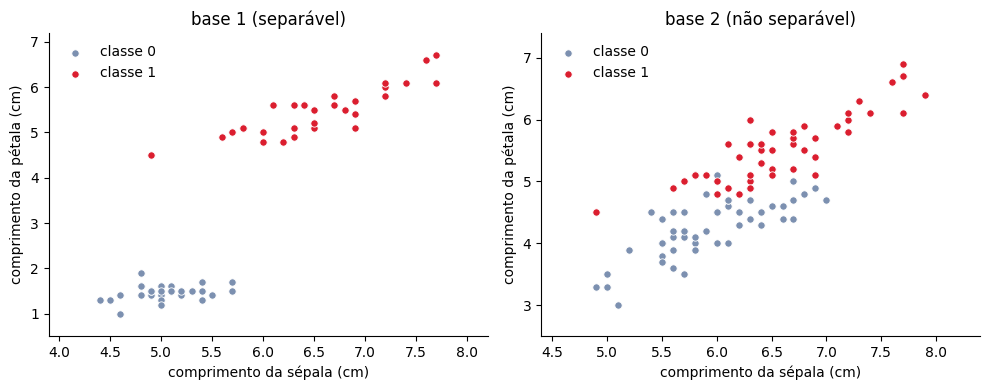

In [6]:
from sklearn.datasets import load_iris

_ATRIB = ["comprimento da sépala (cm)", "largura da sépala (cm)",
          "comprimento da pétala (cm)", "largura da pétala (cm)"]
_ESPECIE = ["setosa", "versicolor", "virginica"]
_PARES = [(0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]


def carrega_bases(matricula):
    """Gera as duas bases do aluno a partir da matrícula. NÃO altere esta função."""
    if not isinstance(matricula, int) or matricula <= 0:
        raise ValueError("Preencha MATRICULA com o seu número de matrícula (só dígitos).")
    iris = load_iris()
    X0, y0 = iris.data, iris.target
    rng = np.random.default_rng(matricula)
    f = list(_PARES[rng.integers(len(_PARES))])
    outra = int(rng.choice([1, 2]))

    # base 1 (separável): 30 setosa + 30 da outra espécie, sorteadas
    idx = np.r_[rng.choice(50, 30, replace=False), 50 * outra + rng.choice(50, 30, replace=False)]
    idx = rng.permutation(idx)
    X_sep = X0[idx][:, f]
    y_sep = (y0[idx] == outra).astype(int)

    # base 2 (não separável): todas as versicolor e virginica, em ordem sorteada
    idx = rng.permutation(np.r_[50:150])
    X_nsep = X0[idx][:, f]
    y_nsep = (y0[idx] == 2).astype(int)

    # questão 1: um par (w, b) que classifica errado o primeiro exemplo da base 1
    while True:
        w_q1 = np.round(rng.uniform(-1, 1, 2), 1)
        b_q1 = float(np.round(rng.uniform(-1, 1), 1))
        z = X_sep[0] @ w_q1 + b_q1
        if np.all(w_q1 != 0) and abs(z) > 0.05 and step(z) != y_sep[0]:
            break

    info = {"atributos": [_ATRIB[i] for i in f],
            "base1": f"setosa (classe 0) x {_ESPECIE[outra]} (classe 1)",
            "base2": "versicolor (classe 0) x virginica (classe 1)"}
    return X_sep, y_sep, X_nsep, y_nsep, w_q1, b_q1, info


X_sep, y_sep, X_nsep, y_nsep, w_q1, b_q1, info = carrega_bases(MATRICULA)
print("atributos:", info["atributos"])
print("base 1:", info["base1"], "| X_sep:", X_sep.shape)
print("base 2:", info["base2"], "| X_nsep:", X_nsep.shape)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
plt.sca(axs[0]); plot_fronteira(X_sep, y_sep, np.zeros(2), 0.0, "base 1 (separável)", info["atributos"])
plt.sca(axs[1]); plot_fronteira(X_nsep, y_nsep, np.zeros(2), 0.0, "base 2 (não separável)", info["atributos"])
plt.tight_layout(); plt.show()

## A1 — Um passo do Perceptron, à mão

Considere o **primeiro exemplo** da base 1, `X_sep[0]`, com rótulo `y_sep[0]`, e o neurônio com os pesos `w_q1` e o bias `b_q1`
abaixo. Use $\eta = 0{,}1$ e a regra da aula:

$$ z = w^\top x + b, \qquad \hat y = \text{step}(z), \qquad w \leftarrow w + \eta\,(y-\hat y)\,x, \qquad b \leftarrow b + \eta\,(y-\hat y) $$

Faça as contas no papel primeiro. Depois, se quiser, confira com código.

In [7]:
print("x =", X_sep[0], "| y =", y_sep[0])
print("w =", w_q1, "| b =", b_q1)

x = [4.9 1.4] | y = 0
w = [-0.3  0.5] | b = 1.0


- **`q1_z`**: o valor de $z$ para esse exemplo.
- **`q1_y_hat`**: a previsão $\hat y$ (0 ou 1).
- **`q1_w_novo`**: o vetor $w$ **depois** de uma atualização, como lista ou array de 2 números.
- **`q1_b_novo`**: o bias **depois** da atualização.

In [8]:
# Faça as contas no papel e digite os resultados. Se quiser, confira com código depois.
# Use: x = X_sep[0], y = y_sep[0], w = w_q1, b = b_q1 e eta = 0.1 (impressos na célula acima).

q1_z = None        # z = w·x + b                        (um número)
q1_y_hat = None    # previsão: step(z)                  (0 ou 1)
q1_w_novo = None   # w + eta * (y - y_hat) * x          (2 números, ex.: [0.5, -1.2])
q1_b_novo = None   # b + eta * (y - y_hat)              (um número)

## A2 — Treinando na base separável

Treine o Perceptron da aula na **base 1** com `eta=0.1`, `epocas=100` e **pesos iniciais zerados** (`init="zeros"`).
Use o histórico retornado para responder:

- **`q2_epocas`**: quantas épocas o treino rodou, contando a última, sem erros.
- **`q2_correcoes`**: o **total** de correções feitas, somando todas as épocas.
- **`q2_w`** e **`q2_b`**: os pesos e o bias finais.

Desenhe também a fronteira encontrada com `plot_fronteira`. O desenho ajuda a conferir o resultado.

In [9]:
# Passo 1: treine o Perceptron da aula na base 1.
#          Apague o # do começo da linha e troque cada ... pelo valor pedido no enunciado.
# w2, b2, hist2 = treina_perceptron(X_sep, y_sep, eta=..., epocas=..., init=...)

# Passo 2: desenhe a fronteira encontrada (apague o # do começo da linha).
# plot_fronteira(X_sep, y_sep, w2, b2, "base 1", info["atributos"]); plt.show()

# Passo 3: responda usando o resultado do treino.
#          hist2 é uma lista com um item por época; cada item é (w, b, correções daquela época).
q2_epocas = None      # quantas épocas o treino rodou
q2_correcoes = None   # soma das correções de todas as épocas
q2_w = None           # pesos finais (2 números)
q2_b = None           # bias final (um número)

## A3 — O papel da taxa de aprendizagem

Treine na **base 1** duas vezes, com `epocas=100` e `init="zeros"`, mudando só a taxa: primeiro `eta=0.5`, depois `eta=8.0`.

- **`q3_epocas`**: quantas épocas o treino rodou com `eta=8.0`.
- **`q3_razao`**: a razão entre os **tamanhos** dos vetores de pesos finais dos dois treinos,
  `np.linalg.norm(w_8) / np.linalg.norm(w_05)`.

Compare as duas fronteiras. Por que, partindo de pesos zerados, a taxa de aprendizagem **não muda a reta** encontrada?

In [10]:
# Passo 1: treine duas vezes na base 1, mudando só a taxa eta.
#          Apague o # do começo das linhas e troque cada ... pelo valor pedido no enunciado.
# wa, ba, hista = treina_perceptron(X_sep, y_sep, eta=0.5, epocas=..., init=...)
# wb, bb, histb = treina_perceptron(X_sep, y_sep, eta=8.0, epocas=..., init=...)

# Passo 2: responda.
q3_epocas = None   # quantas épocas rodou o treino com eta=8.0
q3_razao = None    # tamanho de wb dividido pelo tamanho de wa (use np.linalg.norm)

## A4 — Treinando na base não separável

Agora treine na **base 2** com `eta=0.1`, `epocas=100` e `init="zeros"`. Como a base não é separável, o laço nunca para sozinho.

- **`q4_min_correcoes`**: o **menor** número de correções feitas em uma época, entre as 100.
- **`q4_acuracia_final`**: a fração de flores da base 2 que os pesos **finais** classificam corretamente,
  um número entre 0 e 1. Dica: `np.mean(predizer(...) == y_nsep)`.

Desenhe a fronteira final. Ela é uma boa reta?

In [11]:
# Passo 1: treine o Perceptron da aula na base 2.
#          Apague o # do começo da linha e troque cada ... pelo valor pedido no enunciado.
# w4, b4, hist4 = treina_perceptron(X_nsep, y_nsep, eta=..., epocas=..., init=...)

# Passo 2: desenhe a fronteira final (apague o # do começo da linha).
# plot_fronteira(X_nsep, y_nsep, w4, b4, "base 2", info["atributos"]); plt.show()

# Passo 3: responda.
q4_min_correcoes = None    # o menor número de correções em uma época, olhando todo o hist4
q4_acuracia_final = None   # fração da base 2 que w4 e b4 classificam certo (entre 0 e 1)

## A5 — Extensão: o algoritmo *Pocket*

Na A4, os pesos da **última** época não são necessariamente os melhores: o Perceptron continua corrigindo
e a reta fica pulando de um lado para o outro. O *Pocket* resolve isso guardando "no bolso" a melhor reta já vista.

Escreva a função **`treina_pocket(X, y, eta=0.1, epocas=100)`** a partir do `treina_perceptron` da aula, seguindo
**exatamente** esta especificação:

1. Comece com `w` zerado e `b = 0.0`, e faça as atualizações do Perceptron como na aula, exemplo a exemplo.
2. **Ao fim de cada época**, conte quantos exemplos de `X` a reta atual classifica errado, usando `predizer`.
3. Se esse número for **estritamente menor** que o melhor já visto, guarde uma cópia de `w`, o `b` e o número
   de erros. Em caso de empate, mantenha a reta mais antiga.
4. Se o número de erros chegar a 0, pare o treino.
5. Retorne **três** valores: `w_melhor, b_melhor, erros_melhor`.

Depois, use a função na **base 2** com os valores padrão e responda:

- **`q5_acuracia_pocket`**: a fração da base 2 classificada corretamente pelos pesos do bolso (entre 0 e 1).
- **`q5_melhora`**: `q5_acuracia_pocket - q4_acuracia_final`.

A função será testada em bases que você não conhece, comparando com a especificação acima.

In [12]:
def treina_pocket(X, y, eta=0.1, epocas=100):
    w = np.zeros(X.shape[1])
    b = 0.0
    w_melhor, b_melhor, erros_melhor = w.copy(), b, np.inf    # o "bolso" começa vazio

    for ep in range(epocas):
        # 1. Uma época do Perceptron, como no treina_perceptron da aula:
        #    para cada exemplo (xi, yi), calcule a previsão e, se errar, atualize w e b.

        # 2. Conte quantos exemplos de X a reta atual (w, b) classifica errado. Use predizer.

        # 3. Se esse número for MENOR que erros_melhor, guarde no bolso:
        #    w_melhor = w.copy(), b_melhor = b e erros_melhor = o número de erros.

        # 4. Se o número de erros for 0, pare o treino (break).
        pass

    return w_melhor, b_melhor, erros_melhor

In [13]:
# Passo 1: rode a sua treina_pocket na base 2, com os valores padrão.
w5, b5, erros5 = treina_pocket(X_nsep, y_nsep)

# Passo 2: responda.
q5_acuracia_pocket = None   # fração da base 2 que w5 e b5 classificam certo (entre 0 e 1)
q5_melhora = None           # q5_acuracia_pocket - q4_acuracia_final

# Parte B — MLP e *forward pass*

## 🔒 Os seus dados da Parte B

Esta célula sorteia, a partir da sua matrícula, uma rede pequena para a conta à mão (B1), uma amostra de 120
flores da **Iris**, agora com os **4 atributos** já padronizados e as **3 espécies**, um número `h` de neurônios ocultos e uma
função de ativação `ativ` (B2 e B3).

In [14]:
from sklearn.datasets import load_iris


def carrega_parte_b(matricula):
    """Gera a base e os números da Parte B a partir da matrícula. NÃO altere esta função."""
    if not isinstance(matricula, int) or matricula <= 0:
        raise ValueError("Preencha MATRICULA com o seu número de matrícula (só dígitos).")
    rng = np.random.default_rng(matricula + 1)

    # rede pequena para a conta à mão: 2 entradas, 2 ocultos (ReLU), 2 saídas (softmax)
    while True:
        x_q6 = rng.integers(-2, 3, (1, 2)).astype(float)
        W1_q6 = rng.integers(-2, 3, (2, 2)).astype(float)
        b1_q6 = rng.integers(-1, 2, (1, 2)).astype(float)
        Z1 = x_q6 @ W1_q6 + b1_q6
        if Z1.max() > 0 and Z1.min() < 0:      # um neurônio ativo e outro desligado pela ReLU
            break
    while True:
        W2_q6 = rng.integers(-2, 3, (2, 2)).astype(float)
        Z2 = np.maximum(0, Z1) @ W2_q6
        if Z2[0, 0] != Z2[0, 1]:
            break
    b2_q6 = np.zeros((1, 2))
    classe_q6 = int(rng.integers(2))

    # a mesma Iris da Parte A, agora completa: 120 flores sorteadas, 4 atributos padronizados, 3 espécies
    iris = load_iris()
    idx = rng.permutation(len(iris.target))[:120]
    X_iris = iris.data[idx]
    X_iris = (X_iris - X_iris.mean(axis=0)) / X_iris.std(axis=0)
    y_iris = iris.target[idx]
    h = int(rng.integers(4, 17))
    ativ = str(rng.choice(["sigmoid", "tanh", "relu"]))
    rede = {"x": x_q6, "W1": W1_q6, "b1": b1_q6, "W2": W2_q6, "b2": b2_q6, "classe": classe_q6}
    return rede, X_iris, y_iris, h, ativ


rede, X_iris, y_iris, h, ativ = carrega_parte_b(MATRICULA)
print("X_iris:", X_iris.shape, "| flores por espécie:", np.bincount(y_iris))
print("neurônios ocultos h =", h, "| ativação:", ativ)

X_iris: (120, 4) | flores por espécie: [38 44 38]
neurônios ocultos h = 10 | ativação: sigmoid


## B1 — Um *forward pass* à mão

A rede abaixo tem 2 entradas, uma camada oculta com 2 neurônios **ReLU** e uma saída **softmax** com 2 classes.
Faça as contas no papel, como no exemplo da aula, e só depois confira com o `forward`.

$$ Z^{(1)} = x\,W^{(1)} + b^{(1)}, \qquad A^{(1)} = \text{ReLU}(Z^{(1)}), \qquad Z^{(2)} = A^{(1)} W^{(2)} + b^{(2)}, \qquad \hat y = \text{softmax}(Z^{(2)}) $$

In [15]:
for k in ["x", "W1", "b1", "W2", "b2"]:
    print(f"{k} =", rede[k].tolist())
print("classe correta:", rede["classe"])

x = [[1.0, 2.0]]
W1 = [[-2.0, 0.0], [-1.0, 2.0]]
b1 = [[0.0, -1.0]]
W2 = [[-1.0, 1.0], [0.0, 1.0]]
b2 = [[0.0, 0.0]]
classe correta: 0


- **`q6_z1`**: o vetor $Z^{(1)}$, com 2 números.
- **`q6_a1`**: o vetor $A^{(1)}$, com 2 números.
- **`q6_z2`**: o vetor $Z^{(2)}$, com 2 números.
- **`q6_prob`**: as probabilidades $\hat y$, com 2 números.
- **`q6_perda`**: a entropia cruzada para a classe correta indicada acima, $-\ln \hat y_{\text{classe}}$.

In [16]:
# Faça as contas no papel e digite os resultados. Para conferir depois com o forward da aula:
#   p = {"W1": rede["W1"], "b1": rede["b1"], "W2": rede["W2"], "b2": rede["b2"]}
#   AL, cache = forward(rede["x"], p, "relu")

q6_z1 = None     # Z1 = x W1 + b1                       (2 números)
q6_a1 = None     # A1 = ReLU(Z1)                        (2 números)
q6_z2 = None     # Z2 = A1 W2 + b2                      (2 números)
q6_prob = None   # softmax(Z2)                          (2 números que somam 1)
q6_perda = None  # -ln(probabilidade da classe correta) (um número)

## B2 — A rede antes de treinar

Use a arquitetura `[4, h, 3]`, com o `h` e a ativação `ativ` sorteados para você.

- **`q7_n_params`**: o número total de parâmetros da rede (pesos e biases). Faça a conta à mão e confira com `conta_parametros`.
- **`q7_perda`**: a entropia cruzada da rede **não treinada** em `X_iris`, com `inicializa([4, h, 3], escala=0.01, seed=MATRICULA)`
  e `forward(..., ativ)`. Lembre que `cce` recebe os rótulos em *one-hot*. Compare o valor com $\ln 3$: por que eles são próximos?
- **`q7_saturacao`**: inicialize de novo, agora com `escala=3.0` (mesma `seed`), e calcule a **fração** das entradas de
  $Z^{(1)}$ (no `cache`) com valor absoluto maior que 4, isto é, onde uma sigmoid ou uma tanh estaria saturada.
  Um número entre 0 e 1.

In [17]:
# q7_n_params: conte à mão os números em W1, b1, W2 e b2 da rede [4, h, 3].
q7_n_params = None

# q7_perda: a rede ainda não treinada, com escala=0.01.
params = inicializa([4, h, 3], escala=0.01, seed=MATRICULA)
AL7, cache7 = forward(X_iris, params, ativ)
q7_perda = None       # entropia cruzada: cce(rótulos em one-hot, AL7). Dica: one_hot(y_iris, 3)

# q7_saturacao: a mesma rede, agora com escala=3.0.
params_g = inicializa([4, h, 3], escala=3.0, seed=MATRICULA)
AL_g, cache_g = forward(X_iris, params_g, ativ)
q7_saturacao = None   # fração das entradas de cache_g["Z1"] com valor absoluto maior que 4

## B3 — Extensão: outras camadas de saída

O `forward` da aula sempre termina em softmax. Mas, como vimos, **cada tarefa tem seu par saída-perda**:
linear + MSE para regressão, sigmoid + BCE para classificação binária, softmax + CCE para multiclasse.

Escreva **`forward_geral(X, params, ativacao="relu", saida="softmax")`** a partir do `forward` da aula:

1. As camadas ocultas são **exatamente** como no `forward`.
2. Na camada de saída, calcule `ZL = A @ W + b` e aplique: `softmax` se `saida="softmax"`, `sigmoid` se `saida="sigmoid"`
   e **nenhuma** função (identidade) se `saida="linear"`.
3. Retorne `AL, cache`, com o `cache` preenchido como no `forward` (chaves `A0`, `Z1`, `A1`, ..., `ZL`, `AL`).

A função será testada em redes que você não conhece.

Depois, use-a numa tarefa **binária**: separar as *setosa* (classe 0) das outras duas espécies.

- **`q8_perda_bce`**: com `inicializa([4, h, 1], escala=0.5, seed=MATRICULA)`, `forward_geral(X_iris, ..., ativ, saida="sigmoid")`
  e a `bce`, qual é a perda? Os rótulos são `y_iris == 0`. **Atenção ao shape**: `Y` precisa ter o mesmo shape da saída da rede.

In [18]:
def forward_geral(X, params, ativacao="relu", saida="softmax"):
    # Copie aqui o corpo do forward da aula e mude SÓ a camada de saída:
    #   saida="softmax"  ->  AL = softmax(ZL)      (como na aula)
    #   saida="sigmoid"  ->  AL = sigmoid(ZL)
    #   saida="linear"   ->  AL = ZL               (sem nenhuma função)
    # O cache deve ficar igual ao do forward: A0, Z1, A1, ..., ZL, AL.
    AL, cache = None, None   # apague esta linha quando escrever a função

    return AL, cache

In [19]:
# Passo 1: rede com UMA saída, para a tarefa binária (setosa x outras espécies).
params8 = inicializa([4, h, 1], escala=0.5, seed=MATRICULA)
AL8, cache8 = forward_geral(X_iris, params8, ativ, saida="sigmoid")

# Passo 2: monte os rótulos binários: 1 para setosa (y_iris == 0) e 0 para as outras.
#          Atenção: AL8 tem shape (120, 1). Y8 precisa ter exatamente o mesmo shape.
Y8 = None

# Passo 3: responda.
q8_perda_bce = None   # bce(Y8, AL8)

## 🔒 Verificação final

Esta célula **não** diz se as respostas estão certas. Ela só confere se todas foram preenchidas no formato esperado
e faz testes simples na sua `treina_pocket` (porta AND e XOR) e na sua `forward_geral`.

In [20]:
def verificar():
    g, ok = globals(), True
    def falha(msg):
        nonlocal ok; ok = False; print("✗", msg)
    if not isinstance(g.get("MATRICULA"), int): falha("MATRICULA não preenchida (use só dígitos, sem aspas).")
    formatos = {"q1_z": "número", "q1_y_hat": "0 ou 1", "q1_w_novo": "2 números", "q1_b_novo": "número",
                "q2_epocas": "inteiro", "q2_correcoes": "inteiro", "q2_w": "2 números", "q2_b": "número",
                "q3_epocas": "inteiro", "q3_razao": "número",
                "q4_min_correcoes": "inteiro", "q4_acuracia_final": "entre 0 e 1",
                "q5_acuracia_pocket": "entre 0 e 1", "q5_melhora": "número",
                "q6_z1": "2 números", "q6_a1": "2 números", "q6_z2": "2 números", "q6_prob": "2 números",
                "q6_perda": "número", "q7_n_params": "inteiro", "q7_perda": "número",
                "q7_saturacao": "entre 0 e 1", "q8_perda_bce": "número"}
    for nome, fmt in formatos.items():
        v = g.get(nome)
        try:
            a = np.asarray(v, dtype=float)
            if v is None or np.isnan(a).any(): raise ValueError
            if fmt == "2 números" and a.shape != (2,): raise ValueError
            if fmt != "2 números" and a.shape != (): raise ValueError
            if fmt == "inteiro" and float(a) != int(a): raise ValueError
            if fmt == "0 ou 1" and float(a) not in (0, 1): raise ValueError
            if fmt == "entre 0 e 1" and not 0 <= float(a) <= 1: raise ValueError
        except Exception:
            falha(f"{nome}: esperado {fmt}, encontrado {v!r}")
    X_and = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
    try:
        w, b, e = treina_pocket(X_and, np.array([0, 0, 0, 1]))
        if e != 0 or not np.array_equal(predizer(X_and, w, b), [0, 0, 0, 1]): falha("treina_pocket não resolve a porta AND.")
        w, b, e = treina_pocket(X_and, np.array([0, 1, 1, 0]))
        if e != int(np.sum(predizer(X_and, w, b) != [0, 1, 1, 0])): falha("treina_pocket no XOR: erros_melhor não confere com w_melhor e b_melhor.")
        elif e < 1: falha("treina_pocket no XOR: nenhuma reta acerta os 4 pontos.")
    except Exception as ex:
        falha(f"treina_pocket gerou erro: {type(ex).__name__}: {ex}")
    try:
        P = inicializa([3, 4, 2], escala=0.5, seed=1); Xt = np.ones((5, 3))
        for s, ok_ in [("softmax", lambda A: np.allclose(A.sum(axis=1), 1)), ("sigmoid", lambda A: np.all((A > 0) & (A < 1))),
                       ("linear", lambda A: True)]:
            A, c = forward_geral(Xt, P, "tanh", saida=s)
            if A is None:
                falha("forward_geral ainda não foi escrita."); break
            if A.shape != (5, 2) or not ok_(A) or not np.allclose(c["Z2"], c["A1"] @ P["W2"] + P["b2"]):
                falha(f"forward_geral com saida='{s}' não confere.")
        A, _ = forward_geral(Xt, P, "tanh", saida="softmax")
        if A is not None and not np.allclose(A, forward(Xt, P, "tanh")[0]): falha("forward_geral com saida='softmax' deveria igualar o forward da aula.")
    except Exception as ex:
        falha(f"forward_geral gerou erro: {type(ex).__name__}: {ex}")
    print("✓ Tudo preenchido no formato esperado. Pode baixar o .ipynb e entregar." if ok
          else "\nCorrija os itens acima antes de entregar.")

verificar()

✗ q1_z: esperado número, encontrado None
✗ q1_y_hat: esperado 0 ou 1, encontrado None
✗ q1_w_novo: esperado 2 números, encontrado None
✗ q1_b_novo: esperado número, encontrado None
✗ q2_epocas: esperado inteiro, encontrado None
✗ q2_correcoes: esperado inteiro, encontrado None
✗ q2_w: esperado 2 números, encontrado None
✗ q2_b: esperado número, encontrado None
✗ q3_epocas: esperado inteiro, encontrado None
✗ q3_razao: esperado número, encontrado None
✗ q4_min_correcoes: esperado inteiro, encontrado None
✗ q4_acuracia_final: esperado entre 0 e 1, encontrado None
✗ q5_acuracia_pocket: esperado entre 0 e 1, encontrado None
✗ q5_melhora: esperado número, encontrado None
✗ q6_z1: esperado 2 números, encontrado None
✗ q6_a1: esperado 2 números, encontrado None
✗ q6_z2: esperado 2 números, encontrado None
✗ q6_prob: esperado 2 números, encontrado None
✗ q6_perda: esperado número, encontrado None
✗ q7_n_params: esperado inteiro, encontrado None
✗ q7_perda: esperado número, encontrado None
✗ q7